# Оптимизация CatBoost Discrete-Time Survival — Optuna

In [1]:
import json
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna

from catboost import CatBoostClassifier, Pool
from sksurv.util import Surv
from sksurv.metrics import brier_score

ROOT = Path(r"C:\Users\Ева\Desktop\Хакатон Альфа\AURELIUS\scoring")
DATA_PATH = ROOT / "data/processed/ml_survival_dataset.parquet"
SPLIT_PATH = ROOT / "models/experiments/survival_v3_baseline/splits.npz"
BASELINE_DIR = ROOT / "models/experiments/survival_v3_discrete_time"
EXP_DIR = ROOT / "models/experiments/survival_v3_optuna"
TRIALS_DIR = EXP_DIR / "models"
EXP_DIR.mkdir(parents=True, exist_ok=True)
TRIALS_DIR.mkdir(parents=True, exist_ok=True)

STUDY_NAME = "AURELIUS_Discrete_Time_PD_HPO"
DB_PATH = EXP_DIR / "optuna.db"
STORAGE = f"sqlite:///{DB_PATH.as_posix()}"
N_TRIALS = 12
SEED = 42
TIMES = np.array([12.0, 24.0])
print("Папка:", EXP_DIR)


c:\Users\Ева\Desktop\Хакатон Альфа\AURELIUS\scoring\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Папка: C:\Users\Ева\Desktop\Хакатон Альфа\AURELIUS\scoring\models\experiments\survival_v3_optuna


## Загрузка данных и разбиения

In [2]:
df = pd.read_parquet(DATA_PATH)
with np.load(SPLIT_PATH) as split:
    train_idx = split["train_idx"]
    val_idx = split["val_idx"]
    test_idx = split["test_idx"]

with open(BASELINE_DIR / "features.json", encoding="utf-8") as f:
    fcfg = json.load(f)

MODEL_FEATURES = fcfg["features"]
CAT_FEATURES = fcfg["categorical_features"]
assert "month_on_book" in MODEL_FEATURES
assert "term_months" not in MODEL_FEATURES

df_train = df.iloc[train_idx].reset_index(drop=True)
df_val = df.iloc[val_idx].reset_index(drop=True)

assert set(df_train.borrower_id).isdisjoint(set(df_val.borrower_id))
assert set(df_train.borrower_id).isdisjoint(set(df.iloc[test_idx].borrower_id))
print("Train episodes:", len(df_train), "| Validation:", len(df_val))
print("Признаки:", MODEL_FEATURES)

Train episodes: 140000 | Validation: 30000
Признаки: ['age_months', 'industry', 'entity_type', 'monthly_revenue', 'revenue_trend_12m', 'revenue_volatility', 'operating_margin', 'cash_buffer_months', 'dscr', 'debt_to_revenue', 'prior_overdue_30d', 'requested_amount', 'annual_rate', 'macro_stress', 'month_on_book']


## Формирование помесячных наблюдений

In [3]:
def expand_months(episodes, model_features, with_target=True):
    d = episodes["duration"].to_numpy(dtype=np.int32) if with_target else episodes["term_months"].to_numpy(dtype=np.int32)
    if np.any(d < 1):
        raise ValueError("duration/term_months должны быть положительными")
    ids = np.repeat(np.arange(len(episodes)), d)
    starts = np.repeat(np.cumsum(d) - d, d)
    months = (np.arange(len(ids)) - starts + 1).astype(np.int16)
    X = episodes.iloc[ids][[c for c in model_features if c != "month_on_book"]].reset_index(drop=True).copy()
    X["month_on_book"] = months
    X = X[model_features]
    for col in CAT_FEATURES:
        X[col] = X[col].fillna("UNKNOWN").astype(str)
    if not with_target:
        return X
    ev = episodes["event"].to_numpy(dtype=np.int8)
    y = ((ev[ids] == 1) & (months == d[ids])).astype(np.int8)
    return X, y

X_train, y_train = expand_months(df_train, MODEL_FEATURES)
X_val, y_val = expand_months(df_val, MODEL_FEATURES)
train_pool = Pool(X_train, y_train, cat_features=CAT_FEATURES)
val_pool = Pool(X_val, y_val, cat_features=CAT_FEATURES)
print("Monthly train:", len(X_train), "Monthly validation:", len(X_val))

Monthly train: 2913959 Monthly validation: 628153


## Подготовка горизонтов и IPCW Brier Score

In [4]:
# Для каждой договорной длительности оцениваем горизонты внутри срока кредита.
# Горизонты должны быть строго меньше максимального времени наблюдения.
HORIZONS_BY_TERM = {
    12: [6],
    18: [6, 12],
    24: [6, 12, 18],
    36: [6, 12, 24],
    48: [6, 12, 24, 36],
    60: [6, 12, 24, 36, 48],
}

EVAL_GROUPS = {}
for term, horizons in HORIZONS_BY_TERM.items():
    train_group = df_train.loc[df_train.term_months == term].reset_index(drop=True)
    val_group = df_val.loc[df_val.term_months == term].reset_index(drop=True)
    if train_group.empty or val_group.empty:
        raise ValueError(f"Нет данных для срока {term}")

    y_train_group = Surv.from_arrays(
        event=train_group.event.to_numpy(dtype=bool),
        time=train_group.duration.to_numpy(dtype=float),
    )
    y_val_group = Surv.from_arrays(
        event=val_group.event.to_numpy(dtype=bool),
        time=val_group.duration.to_numpy(dtype=float),
    )
    max_test_time = float(val_group.duration.max())
    valid_horizons = np.array([h for h in horizons if h < max_test_time], dtype=float)
    if not len(valid_horizons):
        raise ValueError(f"Нет допустимых горизонтов для срока {term}")

    EVAL_GROUPS[term] = {
        "n": len(val_group),
        "horizons": valid_horizons,
        "y_train": y_train_group,
        "y_val": y_val_group,
        "X_future": expand_months(val_group, MODEL_FEATURES, with_target=False),
    }

print(pd.DataFrame([
    {"term": term, "validation_episodes": g["n"],
     "horizons": ", ".join(map(lambda x: str(int(x)), g["horizons"]))}
    for term, g in EVAL_GROUPS.items()
]).to_string(index=False))


def evaluate_cumulative_pd(model, return_detail=False):
    details = []
    for term, group in EVAL_GROUPS.items():
        n = group["n"]
        hazard = model.predict_proba(group["X_future"])[:, 1].reshape(n, term)
        hazard = np.clip(hazard, 1e-10, 1 - 1e-10)
        survival = np.cumprod(1.0 - hazard, axis=1)
        horizons = group["horizons"]
        estimates = survival[:, horizons.astype(int) - 1]
        _, scores = brier_score(
            group["y_train"], group["y_val"], estimates, horizons
        )
        for horizon, score in zip(horizons, scores):
            details.append({
                "term_months": int(term),
                "horizon_months": int(horizon),
                "n_episodes": int(n),
                "ipcw_brier": float(score),
            })

    detail_df = pd.DataFrame(details)
    # Среднее по всем (срок, горизонт), взвешенное числом эпизодов.
    # Каждый горизонт учитывается отдельно, что зафиксировано в config.
    objective_value = float(np.average(
        detail_df["ipcw_brier"], weights=detail_df["n_episodes"]
    ))
    if return_detail:
        return objective_value, detail_df
    return objective_value


baseline_model = CatBoostClassifier()
baseline_model.load_model(str(BASELINE_DIR / "model.cbm"))
BASELINE_OBJECTIVE, baseline_detail = evaluate_cumulative_pd(
    baseline_model, return_detail=True
)
baseline_detail.to_csv(EXP_DIR / "baseline_brier_by_horizon.csv", index=False)
print("Baseline objective (все сроки):", round(BASELINE_OBJECTIVE, 6))
display(baseline_detail)

 term  validation_episodes          horizons
   12                 4775                 6
   18                 3864             6, 12
   24                 7239         6, 12, 18
   36                 7185         6, 12, 24
   48                 4196     6, 12, 24, 36
   60                 2741 6, 12, 24, 36, 48
Baseline objective (все сроки): 0.126196


,term_months,horizon_months,n_episodes,ipcw_brier
0,12,6,4775,0.067819
1,18,6,3864,0.066509
2,18,12,3864,0.113796
3,24,6,7239,0.069394
4,24,12,7239,0.116971
5,24,18,7239,0.152131
6,36,6,7185,0.073217
7,36,12,7185,0.124458
8,36,24,7185,0.183440
9,48,6,4196,0.067097


## Подбор гиперпараметров Optuna

In [ ]:
def objective(trial):
    print(f"\nНачинается trial {trial.number}", flush=True)

    params = {
        "iterations": 1200,
        "depth": trial.suggest_int("depth", 4, 8),
        "learning_rate": trial.suggest_float("learning_rate", 0.015, 0.09, log=True),
        "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 1.0, 15.0, log=True),
        "loss_function": "Logloss",
        "eval_metric": "Logloss",
        "random_seed": SEED,
        "early_stopping_rounds": 100,
        "verbose": 100,
        "allow_writing_files": False,
        "task_type": "GPU",
        "devices": "0",
        "gpu_ram_part": 0.8,
    }

    model = CatBoostClassifier(**params)

    model.fit(
        train_pool,
        eval_set=val_pool,
        use_best_model=True
    )

    score, detail = evaluate_cumulative_pd(
        model,
        return_detail=True
    )

    trial.set_user_attr("best_iteration", int(model.best_iteration_))
    trial.set_user_attr(
        "validation_logloss",
        float(model.best_score_["validation"]["Logloss"])
    )
    trial.set_user_attr("mean_weighted_brier", score)

    detail.to_csv(
        EXP_DIR / f"trial_{trial.number:04d}_brier_by_horizon.csv",
        index=False
    )

    model.save_model(
        str(TRIALS_DIR / f"trial_{trial.number:04d}.cbm")
    )

    print(
        f"Trial {trial.number:03d} | "
        f"Weighted IPCW Brier={score:.5f} | "
        f"iter={model.best_iteration_}"
    )

    return score

In [8]:
study = optuna.create_study(
    study_name=STUDY_NAME,
    storage=STORAGE,
    load_if_exists=True,
    direction="minimize",
    sampler=optuna.samplers.TPESampler(seed=SEED),
)

study.optimize(
    objective,
    n_trials=N_TRIALS,
    gc_after_trial=True
)

print("Завершено trials:", len(study.trials))
print("Лучший Optuna score:", study.best_value)
print("Лучшие параметры:", study.best_params)

[I 2026-10-24 16:54:41,631] Using an existing study with `study_name='AURELIUS_Discrete_Time_PD_HPO'` instead of creating a new one.



Начинается trial 1
0:	learn: 0.5337779	test: 0.5336753	best: 0.5336753 (0)	total: 144ms	remaining: 2m 52s
100:	learn: 0.0697801	test: 0.0690815	best: 0.0690815 (100)	total: 5.8s	remaining: 1m 3s
200:	learn: 0.0695517	test: 0.0689314	best: 0.0689314 (200)	total: 11.5s	remaining: 57.2s
300:	learn: 0.0694043	test: 0.0688791	best: 0.0688791 (300)	total: 17.2s	remaining: 51.4s
400:	learn: 0.0692944	test: 0.0688566	best: 0.0688561 (397)	total: 23s	remaining: 45.8s
500:	learn: 0.0691935	test: 0.0688383	best: 0.0688377 (497)	total: 28.9s	remaining: 40.3s
600:	learn: 0.0691024	test: 0.0688295	best: 0.0688292 (593)	total: 34.8s	remaining: 34.7s
700:	learn: 0.0690097	test: 0.0688226	best: 0.0688174 (645)	total: 41s	remaining: 29.2s
bestTest = 0.06881744849
bestIteration = 645
Shrink model to first 646 iterations.


[I 2026-10-24 16:55:31,105] Trial 1 finished with value: 0.12617694120231418 and parameters: {'depth': 5, 'learning_rate': 0.08239308900856526, 'l2_leaf_reg': 7.259248719561363, 'random_strength': 0.7661100707771366}. Best is trial 1 with value: 0.12617694120231418.


Trial 001 | Weighted IPCW Brier=0.12618 | iter=645

Начинается trial 2
0:	learn: 0.6518763	test: 0.6518463	best: 0.6518463 (0)	total: 92.5ms	remaining: 1m 50s
100:	learn: 0.0730713	test: 0.0723887	best: 0.0723887 (100)	total: 5.15s	remaining: 56s
200:	learn: 0.0701658	test: 0.0694289	best: 0.0694289 (200)	total: 10.5s	remaining: 52.2s
300:	learn: 0.0699550	test: 0.0692085	best: 0.0692085 (300)	total: 15.9s	remaining: 47.5s
400:	learn: 0.0698541	test: 0.0691118	best: 0.0691118 (400)	total: 21.3s	remaining: 42.4s
500:	learn: 0.0697838	test: 0.0690481	best: 0.0690481 (499)	total: 27s	remaining: 37.6s
600:	learn: 0.0697301	test: 0.0690043	best: 0.0690043 (600)	total: 32.4s	remaining: 32.3s
700:	learn: 0.0696879	test: 0.0689729	best: 0.0689729 (700)	total: 37.7s	remaining: 26.9s
800:	learn: 0.0696492	test: 0.0689462	best: 0.0689462 (800)	total: 43.2s	remaining: 21.5s
900:	learn: 0.0696157	test: 0.0689243	best: 0.0689243 (900)	total: 48.8s	remaining: 16.2s
1000:	learn: 0.0695857	test: 0.0689

[I 2026-10-24 16:56:41,883] Trial 2 finished with value: 0.1263693901762191 and parameters: {'depth': 4, 'learning_rate': 0.019837118612052406, 'l2_leaf_reg': 1.1703388679635254, 'random_strength': 1.9030368381735812}. Best is trial 1 with value: 0.12617694120231418.


...

Trial 010 | Weighted IPCW Brier=0.12650 | iter=1196

Начинается trial 11
0:	learn: 0.5459567	test: 0.5458488	best: 0.5458488 (0)	total: 279ms	remaining: 5m 34s
100:	learn: 0.0698717	test: 0.0691338	best: 0.0691338 (100)	total: 9.14s	remaining: 1m 39s
200:	learn: 0.0696659	test: 0.0689551	best: 0.0689551 (200)	total: 18.9s	remaining: 1m 34s
300:	learn: 0.0695602	test: 0.0689027	best: 0.0689021 (297)	total: 29s	remaining: 1m 26s
400:	learn: 0.0694707	test: 0.0688687	best: 0.0688687 (400)	total: 40.9s	remaining: 1m 21s
500:	learn: 0.0694034	test: 0.0688511	best: 0.0688504 (497)	total: 53s	remaining: 1m 13s
600:	learn: 0.0693312	test: 0.0688372	best: 0.0688364 (593)	total: 1m 4s	remaining: 1m 4s
700:	learn: 0.0692700	test: 0.0688264	best: 0.0688236 (682)	total: 1m 17s	remaining: 54.8s
800:	learn: 0.0692122	test: 0.0688186	best: 0.0688176 (770)	total: 1m 28s	remaining: 44.3s
900:	learn: 0.0691540	test: 0.0688039	best: 0.0688038 (892)	total: 1m 40s	remaining: 33.5s
1000:	learn: 0.0690899	tes

[I 2026-10-24 17:18:18,120] Trial 11 finished with value: 0.1258742545831902 and parameters: {'depth': 4, 'learning_rate': 0.07559083997834254, 'l2_leaf_reg': 2.5114194159518766, 'random_strength': 2.419622127889926}. Best is trial 9 with value: 0.1258712086656087.


Trial 011 | Weighted IPCW Brier=0.12587 | iter=1169

Начинается trial 12
0:	learn: 0.5326852	test: 0.5325668	best: 0.5325668 (0)	total: 278ms	remaining: 5m 33s
100:	learn: 0.0698440	test: 0.0690807	best: 0.0690807 (100)	total: 9.09s	remaining: 1m 38s
200:	learn: 0.0696471	test: 0.0689383	best: 0.0689383 (200)	total: 19.2s	remaining: 1m 35s
300:	learn: 0.0695322	test: 0.0688835	best: 0.0688819 (298)	total: 29.2s	remaining: 1m 27s
400:	learn: 0.0694469	test: 0.0688669	best: 0.0688648 (398)	total: 39.3s	remaining: 1m 18s
500:	learn: 0.0693747	test: 0.0688500	best: 0.0688485 (490)	total: 52.1s	remaining: 1m 12s
600:	learn: 0.0692956	test: 0.0688209	best: 0.0688209 (600)	total: 1m 7s	remaining: 1m 7s
700:	learn: 0.0692339	test: 0.0688165	best: 0.0688157 (681)	total: 1m 21s	remaining: 57.8s
800:	learn: 0.0691693	test: 0.0688031	best: 0.0688024 (794)	total: 1m 34s	remaining: 47.2s
900:	learn: 0.0691086	test: 0.0688029	best: 0.0687992 (856)	total: 1m 48s	remaining: 35.9s
1000:	learn: 0.0690360

[I 2026-10-24 17:20:31,481] Trial 12 finished with value: 0.12589888421546677 and parameters: {'depth': 4, 'learning_rate': 0.08317647694102732, 'l2_leaf_reg': 1.7871403972583209, 'random_strength': 1.7074777245080337}. Best is trial 9 with value: 0.1258712086656087.


Trial 012 | Weighted IPCW Brier=0.12590 | iter=984
Завершено trials: 13
Лучший Optuna score: 0.1258712086656087
Лучшие параметры: {'depth': 4, 'learning_rate': 0.08212355222166307, 'l2_leaf_reg': 13.666943328202278, 'random_strength': 1.5635108708133456}


## Результаты оптимизации

,number,value,state,params_depth,params_l2_leaf_reg,params_learning_rate,params_random_strength,params_rsm,user_attrs_best_iteration,user_attrs_mean_weighted_brier,user_attrs_validation_logloss
9,9,0.125871,COMPLETE,4,13.666943,0.082124,1.563511,NaN,1062.0,0.125871,0.068774
11,11,0.125874,COMPLETE,4,2.511419,0.075591,2.419622,NaN,1169.0,0.125874,0.068779
12,12,0.125899,COMPLETE,4,1.787140,0.083176,1.707478,NaN,984.0,0.125899,0.068786
7,7,0.126163,COMPLETE,6,1.717254,0.061246,0.574892,NaN,683.0,0.126163,0.068851
1,1,0.126177,COMPLETE,5,7.259249,0.082393,0.766110,NaN,645.0,0.126177,0.068817
5,5,0.126189,COMPLETE,5,3.221119,0.038409,0.269266,NaN,1125.0,0.126189,0.068841
6,6,0.126282,COMPLETE,7,2.205915,0.019259,0.347665,NaN,1199.0,0.126282,0.068862
3,3,0.126299,COMPLETE,7,1.057327,0.053343,2.708161,NaN,537.0,0.126299,0.068881
4,4,0.126301,COMPLETE,8,1.636224,0.021944,0.186600,NaN,1132.0,0.126301,0.068864
2,2,0.126369,COMPLETE,4,1.170339,0.019837,1.903037,NaN,1198.0,0.126369,0.068881


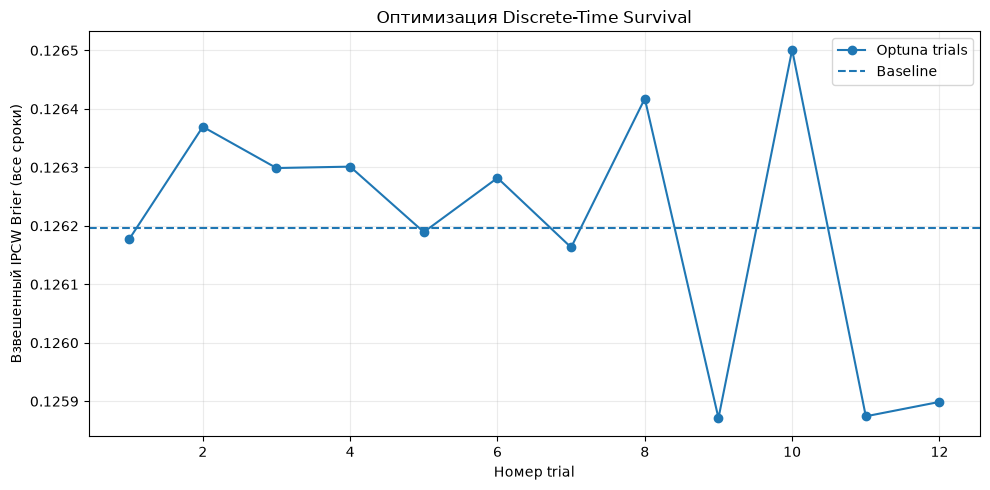

In [10]:
trials_df = study.trials_dataframe(attrs=("number", "value", "state", "params", "user_attrs"))
trials_df.to_csv(EXP_DIR / "optuna_trials.csv", index=False)
completed = trials_df.loc[trials_df["state"] == "COMPLETE"].sort_values("value").copy()
display(completed.head(15))

fig, ax = plt.subplots(figsize=(10, 5))
if len(completed):
    ordered = trials_df.loc[trials_df["state"] == "COMPLETE"].sort_values("number")
    ax.plot(ordered["number"], ordered["value"], marker="o", label="Optuna trials")
ax.axhline(BASELINE_OBJECTIVE, ls="--", label="Baseline")
ax.set_xlabel("Номер trial")
ax.set_ylabel("Взвешенный IPCW Brier (все сроки)")
ax.set_title("Оптимизация Discrete-Time Survival")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(EXP_DIR / "optimization_history.png", dpi=160)
plt.show()

## Сохранение лучшей модели

In [12]:
best_trial = study.best_trial
optuna_model_path = TRIALS_DIR / f"trial_{best_trial.number:04d}.cbm"
baseline_model_path = BASELINE_DIR / "model.cbm"

if float(best_trial.value) < BASELINE_OBJECTIVE:
    winner = "optuna"
    source_model_path = optuna_model_path
    winning_metrics = {"weighted_ipcw_brier": float(best_trial.value)}
    winning_params = best_trial.params
    winning_iteration = best_trial.user_attrs["best_iteration"]
else:
    winner = "baseline"
    source_model_path = baseline_model_path
    winning_metrics = {"weighted_ipcw_brier": BASELINE_OBJECTIVE}
    winning_params = baseline_model.get_params()
    winning_iteration = baseline_model.best_iteration_

shutil.copy2(source_model_path, EXP_DIR / "best_model.cbm")

summary = {
    "winner": winner,
    "optuna_best_trial": int(best_trial.number),
    "optuna_best_value": float(best_trial.value),
    "baseline_weighted_ipcw_brier": BASELINE_OBJECTIVE,
    "selected_metrics": winning_metrics,
    "selected_params": winning_params,
    "selected_best_iteration": int(winning_iteration),
    "selection": "validation; all contractual terms; episode-count weighted mean IPCW Brier across term/horizon pairs",
    "horizons_by_term": HORIZONS_BY_TERM,
    "test_used": False,
    "features": MODEL_FEATURES,
    "categorical_features": CAT_FEATURES,
}
with open(EXP_DIR / "best_config.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=2, default=str)

print("Выбрана модель:", winner)
print("Метрики:", winning_metrics)
print("Модель:", EXP_DIR / "best_model.cbm")
print("Конфигурация:", EXP_DIR / "best_config.json")
selected_model = CatBoostClassifier()
selected_model.load_model(str(EXP_DIR / "best_model.cbm"))
selected_score, selected_detail = evaluate_cumulative_pd(selected_model, return_detail=True)
selected_detail.to_csv(EXP_DIR / "best_brier_by_horizon.csv", index=False)
print("Итоговый weighted IPCW Brier:", selected_score)


Выбрана модель: optuna
Метрики: {'weighted_ipcw_brier': 0.1258712086656087}
Модель: C:\Users\Ева\Desktop\Хакатон Альфа\AURELIUS\scoring\models\experiments\survival_v3_optuna\best_model.cbm
Конфигурация: C:\Users\Ева\Desktop\Хакатон Альфа\AURELIUS\scoring\models\experiments\survival_v3_optuna\best_config.json
Итоговый weighted IPCW Brier: 0.1258712086656087
